<a href="https://colab.research.google.com/github/pratham-239/UCS420/blob/main/Cognitive_Lab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q1

Cleaned Text:
my favorite topic is technology because it makes our lives easier and more efficient artificial intelligence is one of the most interesting developments in modern technology it helps people solve problems analyze data and automate daily tasks i also enjoy learning about programming because it allows me to create useful applications i believe technology will continue to shape the future and create many new opportunities

Sentence Tokenization:
['my favorite topic is technology because it makes our lives easier and more efficient.', 'artificial intelligence is one of the most interesting developments in modern technology.', 'it helps people solve problems, analyze data, and automate daily tasks.', 'i also enjoy learning about programming because it allows me to create useful applications.', 'i believe technology will continue to shape the future and create many new opportunities.']

Word Tokenization:
['my', 'favorite', 'topic', 'is', 'technology', 'because', 'it', 'makes',

<Axes: title={'center': 'Top 10 Words (Excluding Stopwords)'}, xlabel='Samples', ylabel='Counts'>

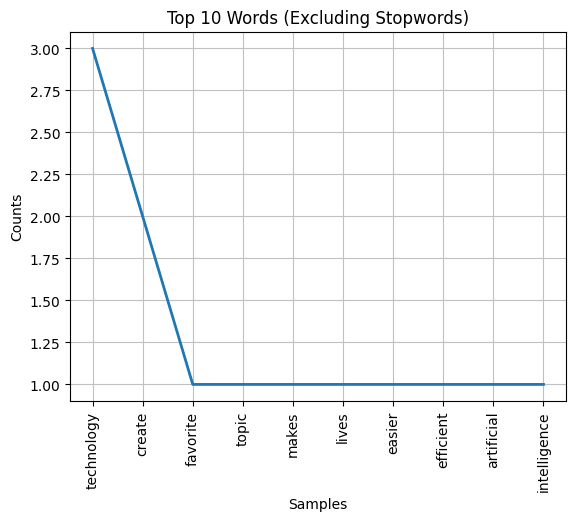

In [6]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# nltk.download('punkt')
# nltk.download('punkt_tab')
# nltk.download('stopwords')

text = """My favorite topic is technology because it makes our lives easier and more efficient. Artificial intelligence is one of the most interesting developments in modern technology. It helps people solve problems, analyze data, and automate daily tasks. I also enjoy learning about programming because it allows me to create useful applications. I believe technology will continue to shape the future and create many new opportunities."""

lower_text = text.lower()

clean_text = re.sub(r'[^\w\s]', '', lower_text)

print("Cleaned Text:")
print(clean_text)

print("\nSentence Tokenization:")
sentences = sent_tokenize(lower_text)
print(sentences)

print("\nWord Tokenization:")
words = word_tokenize(clean_text)
print(words)

print("\nUsing split():")
split_words = lower_text.split()
print(split_words)

print("\nUsing word_tokenize():")
token_words = word_tokenize(lower_text)
print(token_words)

print("\nNumber of words using split():", len(split_words))
print("Number of words using word_tokenize():", len(token_words))

stop_words = set(stopwords.words('english'))

filtered_words = [word for word in words if word not in stop_words]

print("\nWords after removing stopwords:")
print(filtered_words)

frequency = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in frequency.most_common():
    print(word, ":", count)

frequency.plot(10, title="Top 10 Words (Excluding Stopwords)")


Q2

In [11]:
# nltk.download('wordnet')
# nltk.download('omw-1.4')

from nltk.stem import PorterStemmer, WordNetLemmatizer

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Words:")
print(words)

stop_words = set(stopwords.words('english'))

filtered_words = [word for word in words if word not in stop_words]

print("\nAfter Removing Stopwords:")
print(filtered_words)

stemmer = PorterStemmer()

stemmed_words = [stemmer.stem(word) for word in filtered_words]

print("\nStemmed Words:")
print(stemmed_words)

lemmatizer = WordNetLemmatizer()

lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

print("\nLemmatized Words:")
print(lemmatized_words)


Words:
['my', 'favorite', 'topic', 'is', 'technology', 'because', 'it', 'makes', 'our', 'lives', 'easier', 'and', 'more', 'efficient', 'artificial', 'intelligence', 'is', 'one', 'of', 'the', 'most', 'interesting', 'developments', 'in', 'modern', 'technology', 'it', 'helps', 'people', 'solve', 'problems', 'analyze', 'data', 'and', 'automate', 'daily', 'tasks', 'i', 'also', 'enjoy', 'learning', 'about', 'programming', 'because', 'it', 'allows', 'me', 'to', 'create', 'useful', 'applications', 'i', 'believe', 'technology', 'will', 'continue', 'to', 'shape', 'the', 'future', 'and', 'create', 'many', 'new', 'opportunities']

After Removing Stopwords:
['favorite', 'topic', 'technology', 'makes', 'lives', 'easier', 'efficient', 'artificial', 'intelligence', 'one', 'interesting', 'developments', 'modern', 'technology', 'helps', 'people', 'solve', 'problems', 'analyze', 'data', 'automate', 'daily', 'tasks', 'also', 'enjoy', 'learning', 'programming', 'allows', 'create', 'useful', 'applications',

Q3

In [13]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence is changing technology and improving our lives.",
    "Smartphones make communication easy and help people access information.",
    "Machine learning and artificial intelligence are useful in modern technology."
]

count_vectorizer = CountVectorizer()
bow = count_vectorizer.fit_transform(texts)

print("Bag of Words:")
print(count_vectorizer.get_feature_names_out())
print(bow.toarray())

tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Scores:")
print(tfidf.toarray())

words = tfidf_vectorizer.get_feature_names_out()

for i in range(len(texts)):
    scores = tfidf.toarray()[i]
    top_words = scores.argsort()[-3:][::-1]

    print("\nText", i + 1)
    print("Top 3 Keywords:")

    for index in top_words:
        print(words[index], ":", round(scores[index], 3))


Bag of Words:
['access' 'and' 'are' 'artificial' 'changing' 'communication' 'easy'
 'help' 'improving' 'in' 'information' 'intelligence' 'is' 'learning'
 'lives' 'machine' 'make' 'modern' 'our' 'people' 'smartphones'
 'technology' 'useful']
[[0 1 0 1 1 0 0 0 1 0 0 1 1 0 1 0 0 0 1 0 0 1 0]
 [1 1 0 0 0 1 1 1 0 0 1 0 0 0 0 0 1 0 0 1 1 0 0]
 [0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 1 0 1 0 0 0 1 1]]

TF-IDF Scores:
[[0.         0.22190405 0.         0.28574186 0.37571621 0.
  0.         0.         0.37571621 0.         0.         0.28574186
  0.37571621 0.         0.37571621 0.         0.         0.
  0.37571621 0.         0.         0.28574186 0.        ]
 [0.34608857 0.20440549 0.         0.         0.         0.34608857
  0.34608857 0.34608857 0.         0.         0.34608857 0.
  0.         0.         0.         0.         0.34608857 0.
  0.         0.34608857 0.34608857 0.         0.        ]
 [0.         0.20772628 0.35171117 0.26748541 0.         0.
  0.         0.         0.         0.351711

Q4

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence helps machines learn from data.
It is used in healthcare, education and business.
AI can solve problems and automate tasks.
It makes technology smarter and more useful."""

text2 = """Blockchain is a digital technology that stores information.
It records transactions in a secure way.
Blockchain is used in cryptocurrency and banking.
It provides transparency and prevents data changes."""

words1 = re.findall(r'\b[a-zA-Z]+\b', text1.lower())
words2 = re.findall(r'\b[a-zA-Z]+\b', text2.lower())

print("Tokens of Text 1:")
print(words1)

print("\nTokens of Text 2:")
print(words2)

set1 = set(words1)
set2 = set(words2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("\nJaccard Similarity:", round(jaccard, 3))

vectorizer = TfidfVectorizer()
tfidf = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(tfidf[0:1], tfidf[1:2])

print("Cosine Similarity:", round(cosine[0][0], 3))


Tokens of Text 1:
['artificial', 'intelligence', 'helps', 'machines', 'learn', 'from', 'data', 'it', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'ai', 'can', 'solve', 'problems', 'and', 'automate', 'tasks', 'it', 'makes', 'technology', 'smarter', 'and', 'more', 'useful']

Tokens of Text 2:
['blockchain', 'is', 'a', 'digital', 'technology', 'that', 'stores', 'information', 'it', 'records', 'transactions', 'in', 'a', 'secure', 'way', 'blockchain', 'is', 'used', 'in', 'cryptocurrency', 'and', 'banking', 'it', 'provides', 'transparency', 'and', 'prevents', 'data', 'changes']

Jaccard Similarity: 0.167
Cosine Similarity: 0.309


Q5

,Review,Polarity,Subjectivity,Sentiment
0,This smartphone has an amazing camera and exce...,0.700000,0.833333,Positive
1,The headphones are very poor. The sound qualit...,-0.121667,0.586667,Negative
2,The laptop is okay. It has average performance...,0.166667,0.516667,Positive


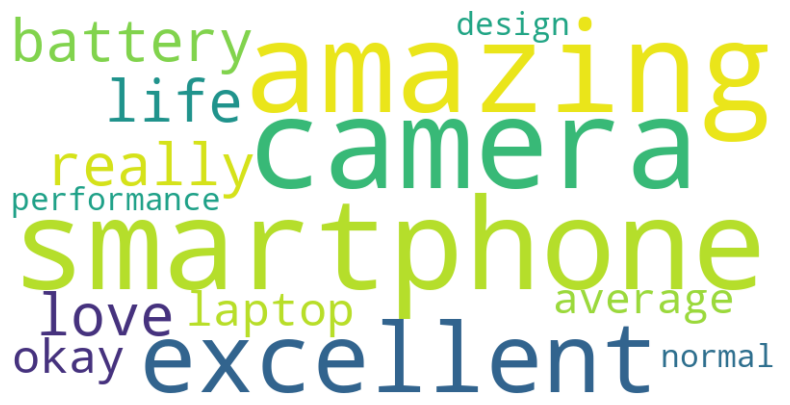

In [15]:
from textblob import TextBlob
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This smartphone has an amazing camera and excellent battery life. I really love it.",
    "The headphones are very poor. The sound quality is bad and the battery drains quickly.",
    "The laptop is okay. It has average performance and a normal design."
]

results = []
positive_reviews = []

for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    results.append([review, polarity, subjectivity, sentiment])

df = pd.DataFrame(results, columns=[
    "Review", "Polarity", "Subjectivity", "Sentiment"
])

display(df)

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()


Q6

In [17]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """Technology is changing the world every day. Artificial intelligence helps people solve problems. Computers make work faster and easier. Machine learning allows computers to learn from data. The internet connects people around the world. Smartphones help us communicate and share information. Technology is useful in education, healthcare and business. Learning programming helps us understand computers. New inventions make our lives better. Technology will continue to improve our future."""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

words = tokenizer.texts_to_sequences([text])[0]

sequences = []

for i in range(2, len(words)):
    sequences.append(words[:i+1])

max_length = max(len(seq) for seq in sequences)

sequences = pad_sequences(sequences, maxlen=max_length, padding='pre')

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential()
model.add(Embedding(len(tokenizer.word_index) + 1, 10, input_length=max_length-1))
model.add(LSTM(50))
model.add(Dense(len(tokenizer.word_index) + 1, activation='softmax'))

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model.fit(X, y, epochs=100, verbose=0)

seed_text = "technology"

for i in range(3):
    sequence = tokenizer.texts_to_sequences([seed_text])[0]
    sequence = pad_sequences([sequence], maxlen=max_length-1, padding='pre')

    prediction = model.predict(sequence, verbose=0)
    predicted_word = tokenizer.index_word[np.argmax(prediction)]

    seed_text = seed_text + " " + predicted_word

    if predicted_word.endswith("."):
        break

print("Generated Text:")
print(seed_text)


Generated Text:
technology intelligence intelligence day
